In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

In [3]:
historyCall_df_cleaned = pd.read_csv('../../data/historyCalls/interim/historyCalls_cleaned.csv',sep=';')
historyCall_df_cleaned.head()


,ward,type,cancelPerson,personLocation,zone,id,personType,timestamp,area,responseTime,...,name,cancelLocation,triggeredBy,is_cancelled,date,hour,dayofweek,shift,staying_time,staying_time_minutes
0,2V ZONE 2A,Normal,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,unknown,unknown,72733,Unknown,2024-01-31 03:49:14+00:00,unknown,11360000000,...,Normale oproep,K 205,NaN,True,2024-01-31,3,2,night,1136.000000,18.933333
1,2V ZONE 2A,Normal,429b91b1e5f922997e21479cdfaa7415ff27594ac74922...,unknown,unknown,72734,Unknown,2024-01-31 03:51:47+00:00,unknown,8610000000,...,Normale oproep,K 223,NaN,True,2024-01-31,3,2,night,861.000000,14.350000
2,unknown,Care,caba69daba2592b14e91e749f2c6c3f6a7c4b0b9d0a034...,2V ZONE 2A,ZONE 2A,72735,Patient,2024-01-31 04:21:31.109643100+00:00,2A_K 221,239625005,...,Draadloze oproep,2A_K 221,NaN,True,2024-01-31,4,2,night,23.962501,0.399375
3,2V ZONE 2A,Normal,b49560dc6e0ffe0b7abc6a018ecde994d0c1b1e571464d...,unknown,unknown,72736,Unknown,2024-01-31 04:57:18+00:00,unknown,7840000000,...,Normale oproep,K 217,NaN,True,2024-01-31,4,2,night,784.000000,13.066667
4,unknown,Care,6ba2e0fb8d826021563d2bab9489a0dea5d0046ea49c7e...,2V ZONE 2B,ZONE 2B,72737,Patient,2024-01-31 05:20:51.108499700+00:00,2B_K 233,1954378464,...,Draadloze oproep,2B_K 233,NaN,True,2024-01-31,5,2,night,195.437846,3.257297


In [8]:
# calculate outlier thresholds
def calculate_type_outlier_summary(df, duration_col='staying_time', type_col='type', iqr_multiplier=1.5):
    summary = []
    
    for call_type in sorted(df[type_col].unique()):
        type_data = df[df[type_col] == call_type]
        duration_data = type_data[duration_col].dropna()
        
        if len(duration_data) > 0:
            q1 = duration_data.quantile(0.25)
            q3 = duration_data.quantile(0.75)
            iqr = q3 - q1
            outlier_threshold = q3 + (iqr_multiplier * iqr)
            
            outlier_count = (duration_data > outlier_threshold).sum()
            outlier_pct = (outlier_count / len(duration_data) * 100)
            
            summary.append({
                'type': call_type,
                'total rows': len(type_data),
                'duration': len(duration_data),
                'mean': duration_data.mean() / 60,
                'median': duration_data.median() / 60,
                'max': duration_data.max() / 60,
                'outlier threshold': outlier_threshold,
                'outliers count': outlier_count,
                'outlier': outlier_pct
            })
    
    return pd.DataFrame(summary)


type_summary_df = calculate_type_outlier_summary(historyCall_df_cleaned)

print(type_summary_df.to_string(index=False))

              type  total rows  duration       mean    median          max  outlier threshold  outliers count   outlier
        Assistance         723       720  40.662146  1.616667  8577.137434         976.301139              70  9.722222
              Care       19718     19552   9.749571  6.645198  1292.478378        1583.021849            1101  5.631137
        LowBattery         281       274  35.352183 14.982577   481.156675        4711.910907              17  6.204380
            Normal       12879     12692  25.922744  4.900000 28833.922896        1368.322121             774  6.098330
             Panic          19        19 275.724881  0.179226  3516.527972         146.600871               4 21.052632
           PullOut        1015       998   4.544142  0.925000    77.333333         782.625000              93  9.318637
          Sanitary        1291      1273  26.412470  3.683333  7061.200000         984.000000              77  6.048704
SanitaryAssistance         903       896

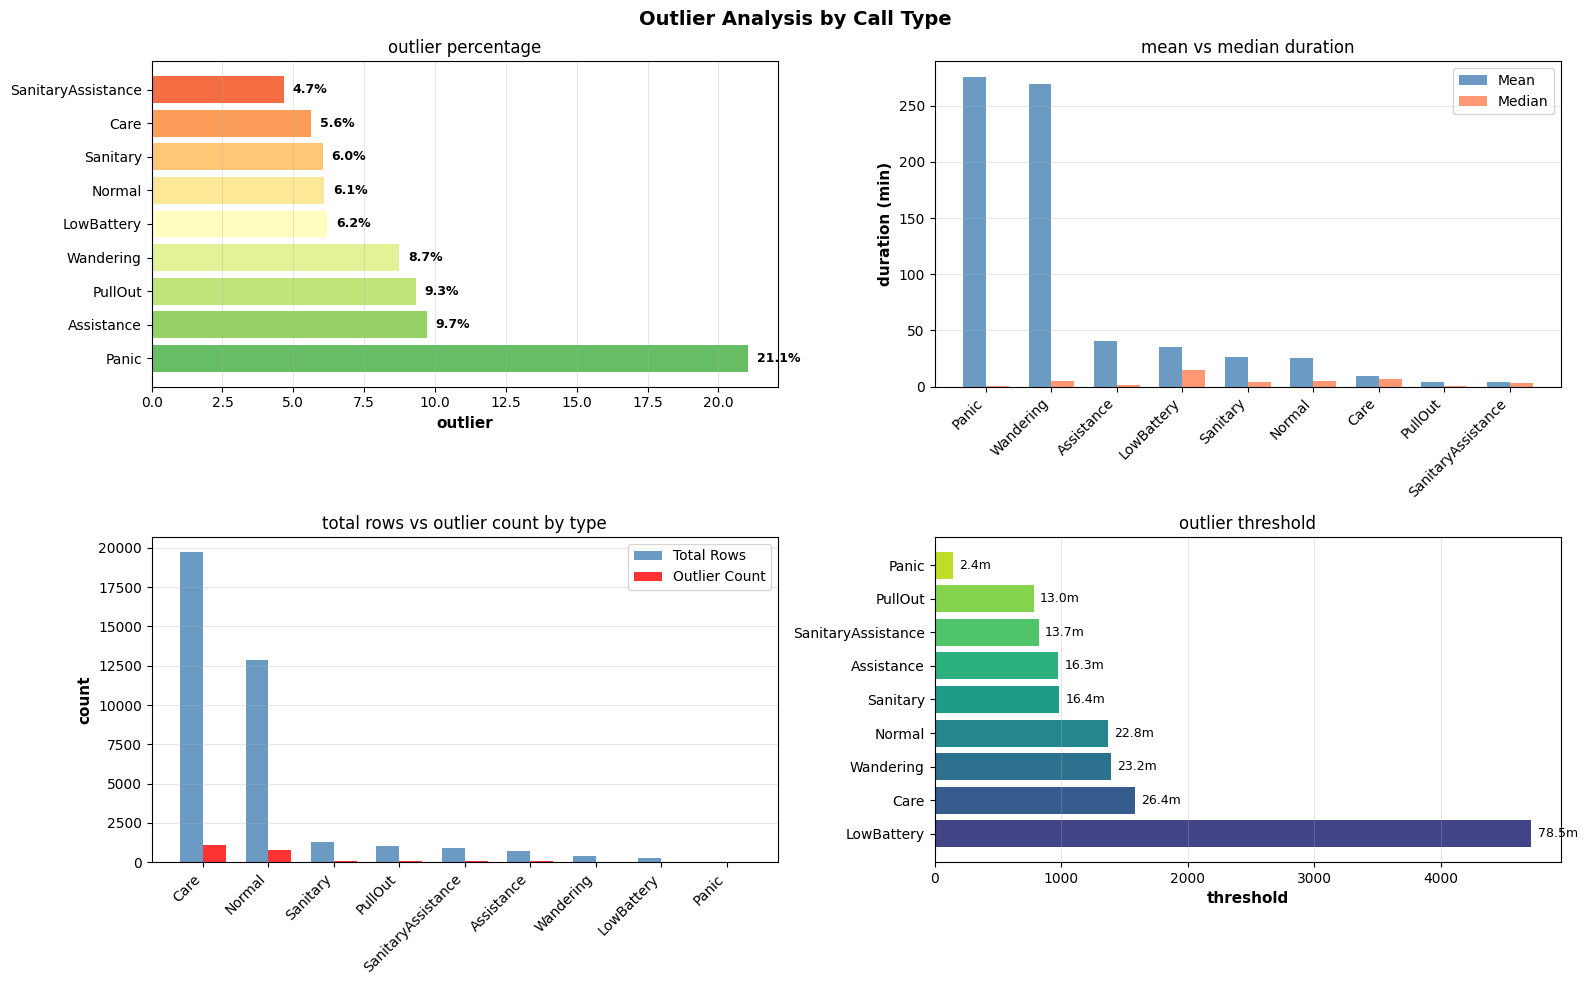

In [12]:
def plot_type_outlier_analysis(summary_df, title='Outlier Analysis by Call Type', figsize=(16, 10)):
    
    fig, axes = plt.subplots(2, 2, figsize=figsize)
    fig.suptitle(title, fontsize=14, fontweight='bold')
    
    # outlier percentage
    ax1 = axes[0, 0]
    sorted_by_outlier = summary_df.sort_values('outlier', ascending=False)
    colors1 = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(sorted_by_outlier)))
    bars1 = ax1.barh(sorted_by_outlier['type'], sorted_by_outlier['outlier'], color=colors1)
    ax1.set_xlabel('outlier', fontsize=11, fontweight='bold')
    ax1.set_title('outlier percentage', fontsize=12)
    ax1.grid(axis='x', alpha=0.3)
    for i, (idx, row) in enumerate(sorted_by_outlier.iterrows()):
        ax1.text(row['outlier'] + 0.3, i, f"{row['outlier']:.1f}%", 
                 va='center', fontsize=9, fontweight='bold')
    
    # mean vs median duration
    ax2 = axes[0, 1]
    sorted_by_mean = summary_df.sort_values('mean', ascending=False)
    x_pos = np.arange(len(sorted_by_mean))
    width = 0.35
    bars_mean = ax2.bar(x_pos - width/2, sorted_by_mean['mean'], width, 
                        label='Mean', color='steelblue', alpha=0.8)
    bars_median = ax2.bar(x_pos + width/2, sorted_by_mean['median'], width, 
                          label='Median', color='coral', alpha=0.8)
    ax2.set_ylabel('duration (min)', fontsize=11, fontweight='bold')
    ax2.set_title('mean vs median duration', fontsize=12)
    ax2.set_xticks(x_pos)
    ax2.set_xticklabels(sorted_by_mean['type'], rotation=45, ha='right')
    ax2.legend()
    ax2.grid(axis='y', alpha=0.3)
    
    # total rows vs outliers count
    ax3 = axes[1, 0]
    sorted_by_rows = summary_df.sort_values('total rows', ascending=False)
    x_pos = np.arange(len(sorted_by_rows))
    bars_total = ax3.bar(x_pos - width/2, sorted_by_rows['total rows'], width, 
                         label='Total Rows', color='steelblue', alpha=0.8)
    bars_outliers = ax3.bar(x_pos + width/2, sorted_by_rows['outliers count'], width, 
                            label='Outlier Count', color='red', alpha=0.8)
    ax3.set_ylabel('count', fontsize=11, fontweight='bold')
    ax3.set_title('total rows vs outlier count by type', fontsize=12)
    ax3.set_xticks(x_pos)
    ax3.set_xticklabels(sorted_by_rows['type'], rotation=45, ha='right')
    ax3.legend()
    ax3.grid(axis='y', alpha=0.3)
    
    # outlier threshold
    ax4 = axes[1, 1]
    sorted_by_threshold = summary_df.sort_values('outlier threshold', ascending=False)
    colors4 = plt.cm.viridis(np.linspace(0.2, 0.9, len(sorted_by_threshold)))
    bars4 = ax4.barh(sorted_by_threshold['type'], sorted_by_threshold['outlier threshold'], color=colors4)
    ax4.set_xlabel('threshold', fontsize=11, fontweight='bold')
    ax4.set_title('outlier threshold', fontsize=12)
    ax4.grid(axis='x', alpha=0.3)
    for i, (idx, row) in enumerate(sorted_by_threshold.iterrows()):
        threshold_min = row['outlier threshold'] / 60
        ax4.text(row['outlier threshold'] + 50, i, f'{threshold_min:.1f}m', 
                 va='center', fontsize=9)
    
    plt.tight_layout()
    plt.show()


plot_type_outlier_analysis(type_summary_df)

In [13]:
# helper function
def plot_type_boxplot(ax, duration_data, call_type, show_legend=False, iqr_multiplier=1.5):
    if len(duration_data) == 0:
        ax.text(0.5, 0.5, f'No data for {call_type}', ha='center', va='center',
               transform=ax.transAxes)
        ax.set_title(f'{call_type}', fontsize=11, fontweight='bold')
        return
    
    # outlier threshold
    q1 = duration_data.quantile(0.25)
    q3 = duration_data.quantile(0.75)
    iqr = q3 - q1
    outlier_threshold = q3 + (iqr_multiplier * iqr)
    
    # separate outliers and normal values
    outliers_mask = duration_data > outlier_threshold
    normal_vals = duration_data[~outliers_mask]
    outlier_vals = duration_data[outliers_mask]
    
    bp = ax.boxplot([duration_data], labels=[call_type], patch_artist=True,
                    widths=0.5, showfliers=False)
    
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)
    for median in bp['medians']:
        median.set(color='darkred', linewidth=2)
    
    if len(normal_vals) > 0:
        ax.scatter([1] * len(normal_vals), normal_vals, alpha=0.4, s=30, 
                  color='steelblue', label='Normal', zorder=3)
    if len(outlier_vals) > 0:
        ax.scatter([1] * len(outlier_vals), outlier_vals, alpha=0.8, s=50, 
                  color='red', marker='X', label='Outlier', zorder=4)
    
    ax.axhline(y=outlier_threshold, color='orange', linestyle='--', linewidth=1.5, 
               alpha=0.7, label=f'Threshold: {outlier_threshold/60:.1f} min')
    
    # stats text box
    outlier_count = len(outlier_vals)
    outlier_pct = (outlier_count / len(duration_data) * 100)
    stats_text = f'n={len(duration_data)}\nNormal: {len(normal_vals)}\nOutliers: {outlier_count} ({outlier_pct:.1f}%)'
    ax.text(1.35, ax.get_ylim()[1] * 0.95, stats_text, fontsize=9, 
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    ax.set_ylabel('Staying Time (seconds)', fontsize=10)
    ax.set_title(f'{call_type}', fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    
    if show_legend:
        ax.legend(loc='upper left', fontsize=8)

C:\Users\S_YZH\AppData\Local\Temp\ipykernel_24808\2588610173.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([duration_data], labels=[call_type], patch_artist=True,
C:\Users\S_YZH\AppData\Local\Temp\ipykernel_24808\2588610173.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([duration_data], labels=[call_type], patch_artist=True,
C:\Users\S_YZH\AppData\Local\Temp\ipykernel_24808\2588610173.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([duration_data], labels=[call_type], patch_artist=True,
C:\Users\S_YZH\AppData\Local\Temp\ipykernel_24808\2588610173.py:20:

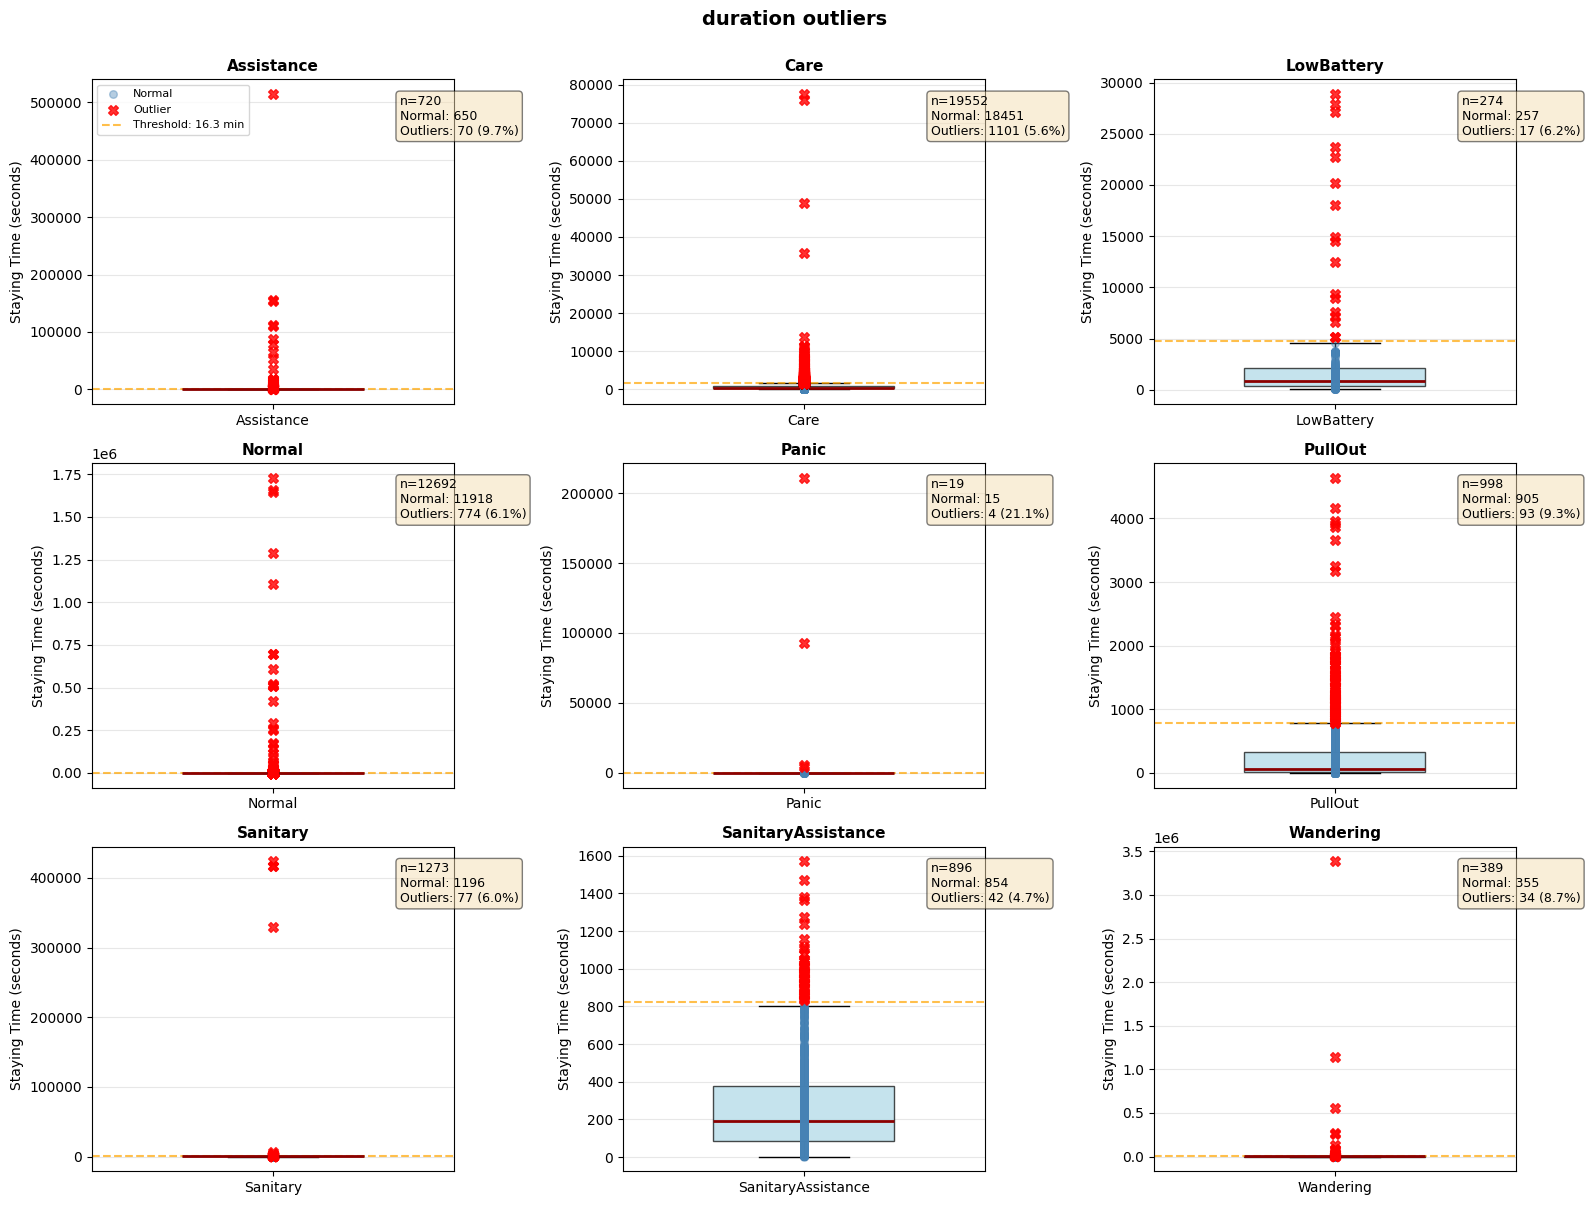

In [14]:
def plot_type_boxplot_grid(df, type_col='type', duration_col='staying_time', title='duration outliers', figsize=(16, 12), ncols=3):

    types_sorted = sorted(df[type_col].unique())
    n_types = len(types_sorted)
    nrows = (n_types + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = axes.flatten()
    
    for idx, call_type in enumerate(types_sorted):
        ax = axes[idx]
        type_data = df[df[type_col] == call_type]
        duration_data = type_data[duration_col].dropna()
        
        # plot individual type
        plot_type_boxplot(ax, duration_data, call_type, show_legend=(idx == 0))
    
    # remove empty subplots
    for idx in range(n_types, len(axes)):
        fig.delaxes(axes[idx])
    
    fig.suptitle(title, fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

plot_type_boxplot_grid(historyCall_df_cleaned)

1. call over time

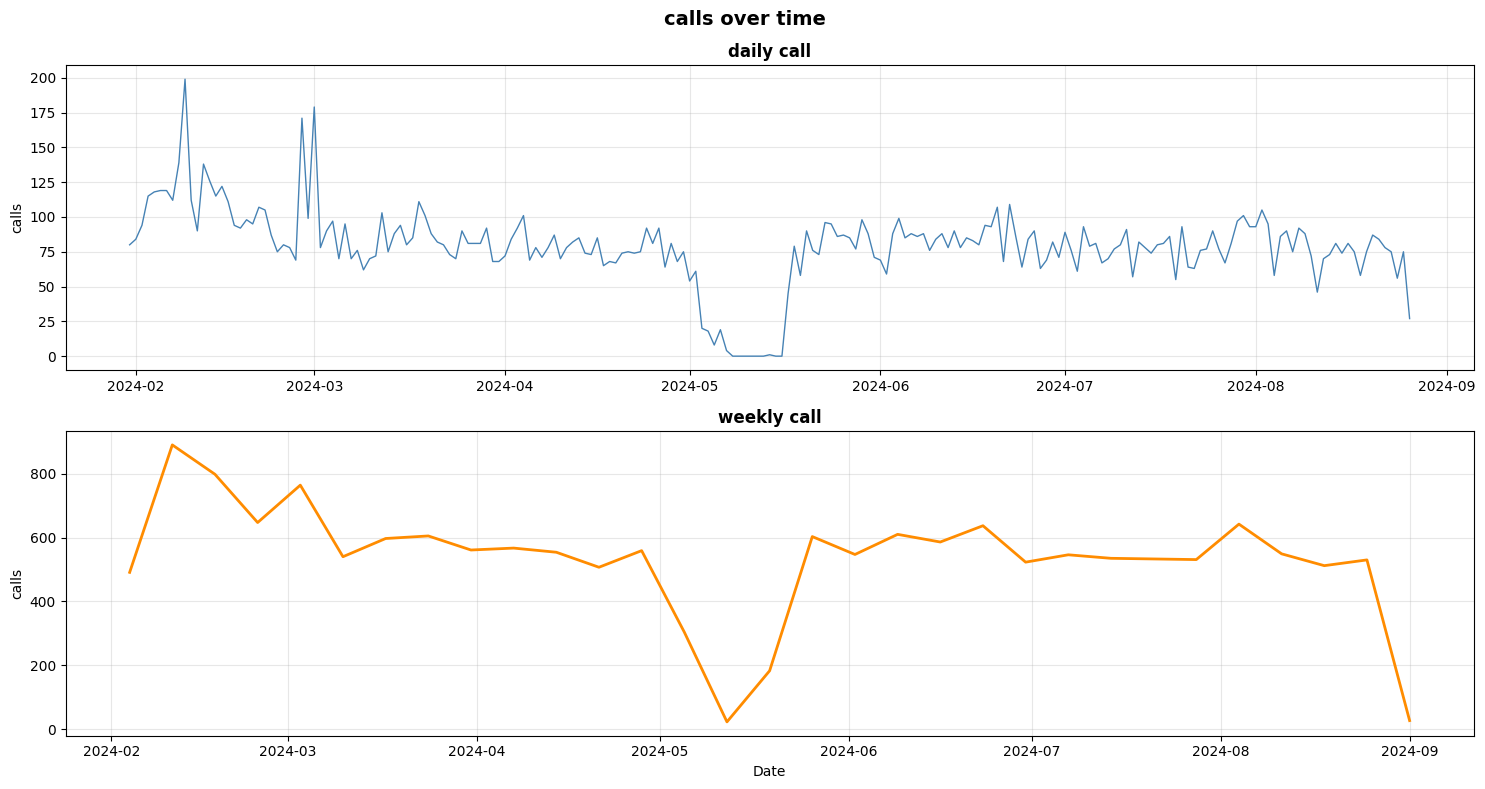

In [15]:
def prepare_calls_over_time(df, ts_col='timestamp', freq='D'):
    ts = pd.to_datetime(df[ts_col], errors='coerce', utc=True)
    series = pd.Series(1, index=ts).dropna()
    counts = series.resample(freq).sum().fillna(0)
    return counts


def plot_calls_over_time(df, ts_col='timestamp'):
    daily_counts = prepare_calls_over_time(df, ts_col=ts_col, freq='D')
    weekly_counts = prepare_calls_over_time(df, ts_col=ts_col, freq='W')

    fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=False)

    axes[0].plot(daily_counts.index, daily_counts.values, color='steelblue', linewidth=1)
    axes[0].set_title('daily call', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('calls')
    axes[0].grid(alpha=0.3)

    axes[1].plot(weekly_counts.index, weekly_counts.values, color='darkorange', linewidth=2)
    axes[1].set_title('weekly call', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('calls')
    axes[1].set_xlabel('Date')
    axes[1].grid(alpha=0.3)

    plt.suptitle('calls over time', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_calls_over_time(historyCall_df_cleaned)

2. hour&weekday heatmap

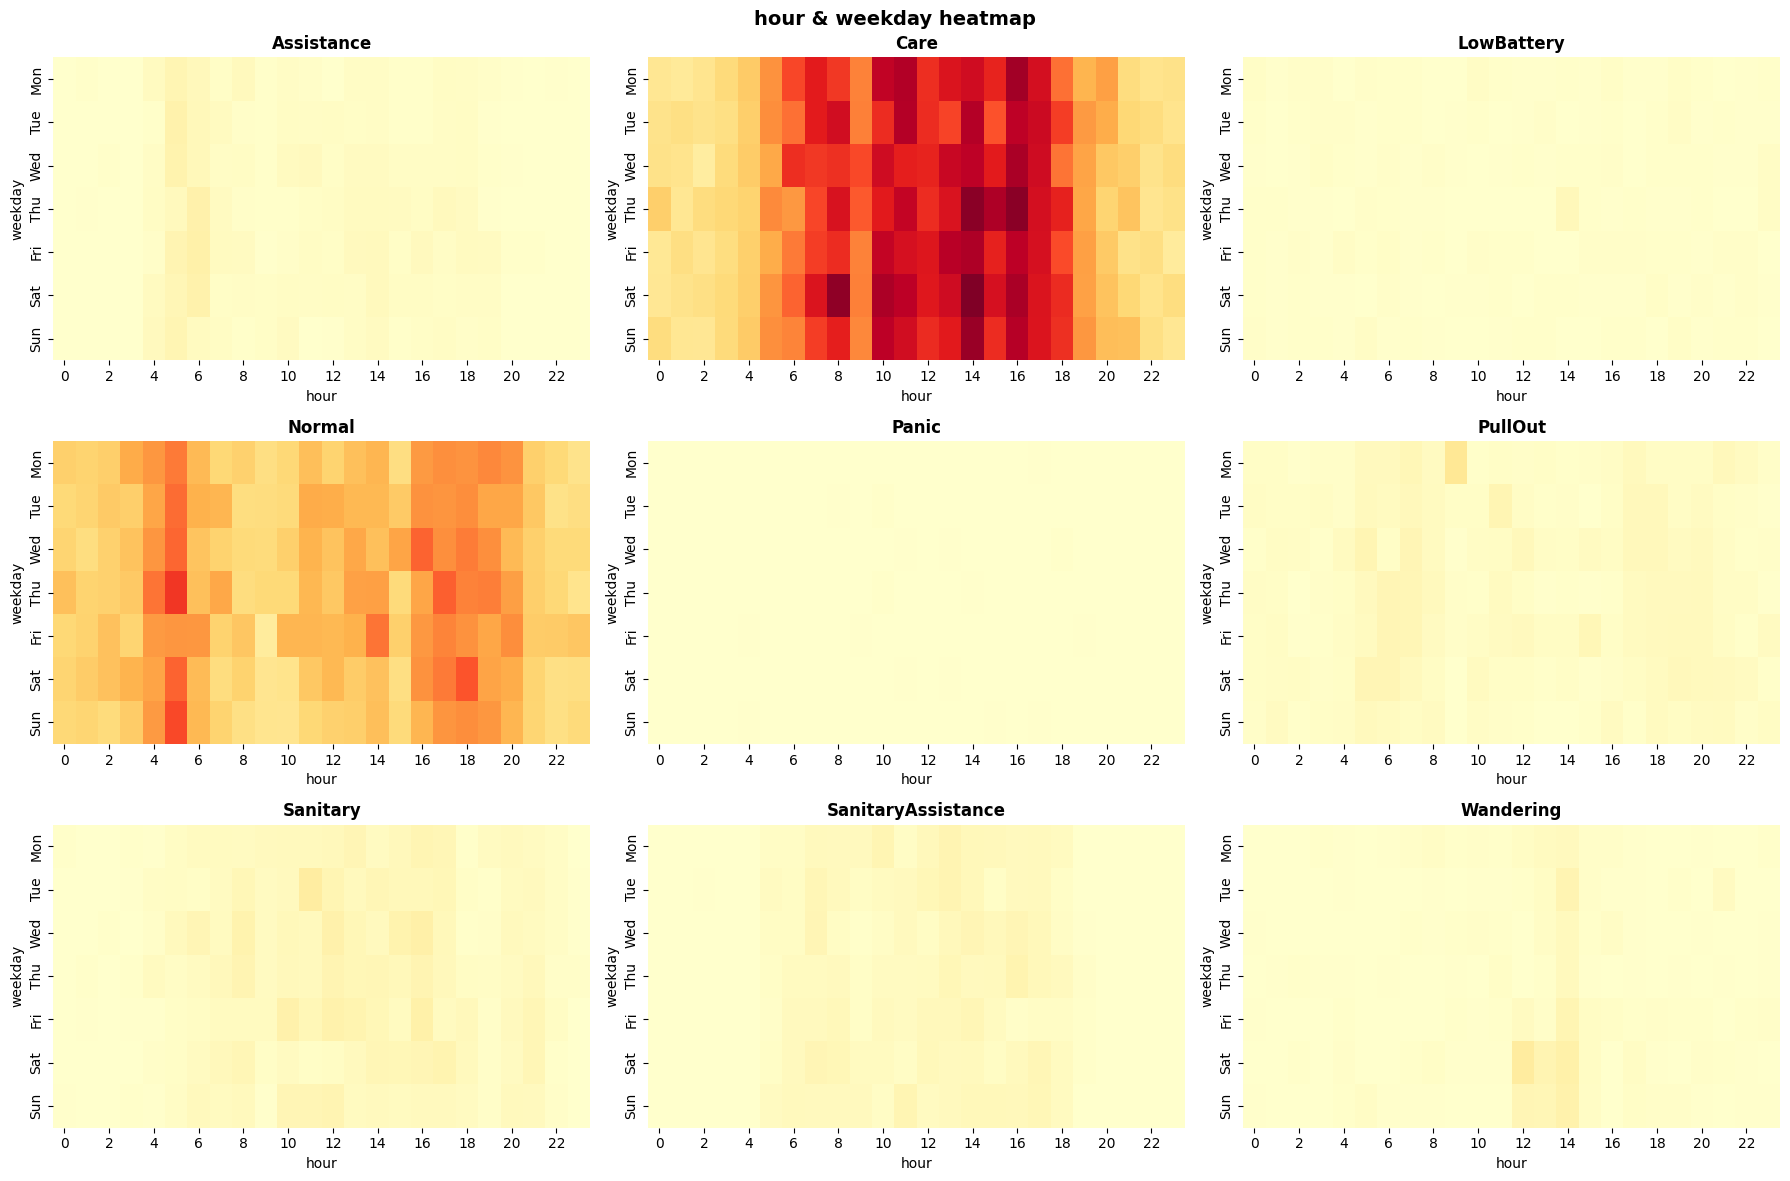

In [16]:
def prepare_hour_weekday_matrix(df, type_value, type_col='type', hour_col='hour', weekday_col='dayofweek'):
    type_df = df[df[type_col] == type_value].copy()
    pivot = pd.pivot_table(
        type_df,
        index=weekday_col,
        columns=hour_col,
        values='id',
        aggfunc='count',
        fill_value=0
    )
    pivot = pivot.reindex(index=range(7), fill_value=0)
    pivot = pivot.reindex(columns=range(24), fill_value=0)
    return pivot


def plot_hour_weekday_heatmap_by_type(df, type_col='type'):
    type_values = sorted(df[type_col].dropna().unique())
    n_types = len(type_values)
    ncols = 3
    nrows = (n_types + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    weekday_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

    vmax = 0
    matrices = {}
    for t in type_values:
        mat = prepare_hour_weekday_matrix(df, t, type_col=type_col)
        matrices[t] = mat
        vmax = max(vmax, mat.values.max())

    for idx, t in enumerate(type_values):
        ax = axes[idx]
        mat = matrices[t]
        sns.heatmap(
            mat,
            ax=ax,
            cmap='YlOrRd',
            cbar=False,
            vmin=0,
            vmax=vmax,
            xticklabels=2,
            yticklabels=weekday_labels
        )
        ax.set_title(f'{t}', fontweight='bold')
        ax.set_xlabel('hour')
        ax.set_ylabel('weekday')

    for idx in range(n_types, len(axes)):
        fig.delaxes(axes[idx])

    plt.suptitle('hour & weekday heatmap', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_hour_weekday_heatmap_by_type(historyCall_df_cleaned)

3. concellation delay distri

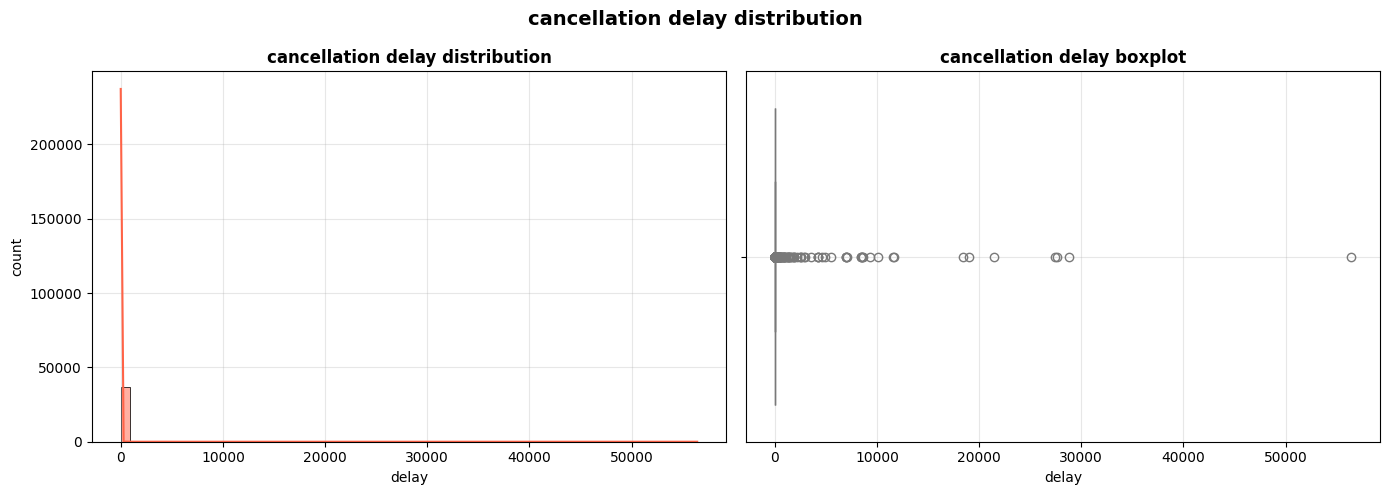

In [17]:
def get_cancellation_delay_minutes(df, cancel_flag_col='is_cancelled', duration_col='staying_time'):
    cancelled = df[df[cancel_flag_col] == True].copy()
    delay_minutes = cancelled[duration_col].dropna() / 60
    return delay_minutes


def plot_cancellation_delay_distribution(df):
    delay_minutes = get_cancellation_delay_minutes(df)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.histplot(delay_minutes, bins=60, kde=True, ax=axes[0], color='tomato')
    axes[0].set_title('cancellation delay distribution', fontweight='bold')
    axes[0].set_xlabel('delay')
    axes[0].set_ylabel('count')
    axes[0].grid(alpha=0.3)

    sns.boxplot(x=delay_minutes, ax=axes[1], color='lightblue')
    axes[1].set_title('cancellation delay boxplot', fontweight='bold')
    axes[1].set_xlabel('delay')
    axes[1].grid(alpha=0.3)

    plt.suptitle('cancellation delay distribution', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_cancellation_delay_distribution(historyCall_df_cleaned)

4. shift comparison

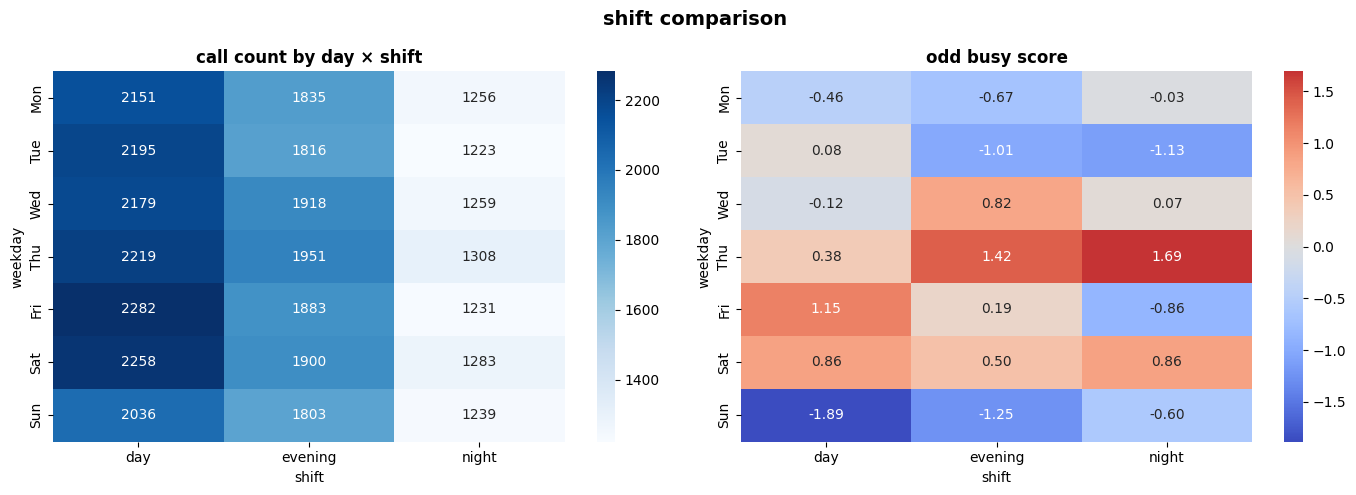

In [18]:
def prepare_shift_day_matrix(df, day_col='dayofweek', shift_col='shift'):
    pivot = pd.pivot_table(df, index=day_col, columns=shift_col, values='id', aggfunc='count', fill_value=0)
    pivot = pivot.reindex(index=range(7), fill_value=0)
    return pivot


def zscore_by_column(pivot_df):
    return (pivot_df - pivot_df.mean(axis=0)) / pivot_df.std(axis=0).replace(0, np.nan)


def plot_shift_day_busy(df):
    raw = prepare_shift_day_matrix(df)
    zmat = zscore_by_column(raw)

    weekday_labels = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.heatmap(raw, annot=True, fmt='g', cmap='Blues', ax=axes[0], yticklabels=weekday_labels)
    axes[0].set_title('call count by day × shift', fontweight='bold')
    axes[0].set_xlabel('shift')
    axes[0].set_ylabel('weekday')

    sns.heatmap(zmat, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1], yticklabels=weekday_labels)
    axes[1].set_title('odd busy score', fontweight='bold')
    axes[1].set_xlabel('shift')
    axes[1].set_ylabel('weekday')

    plt.suptitle('shift comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_shift_day_busy(historyCall_df_cleaned)

5. control chart

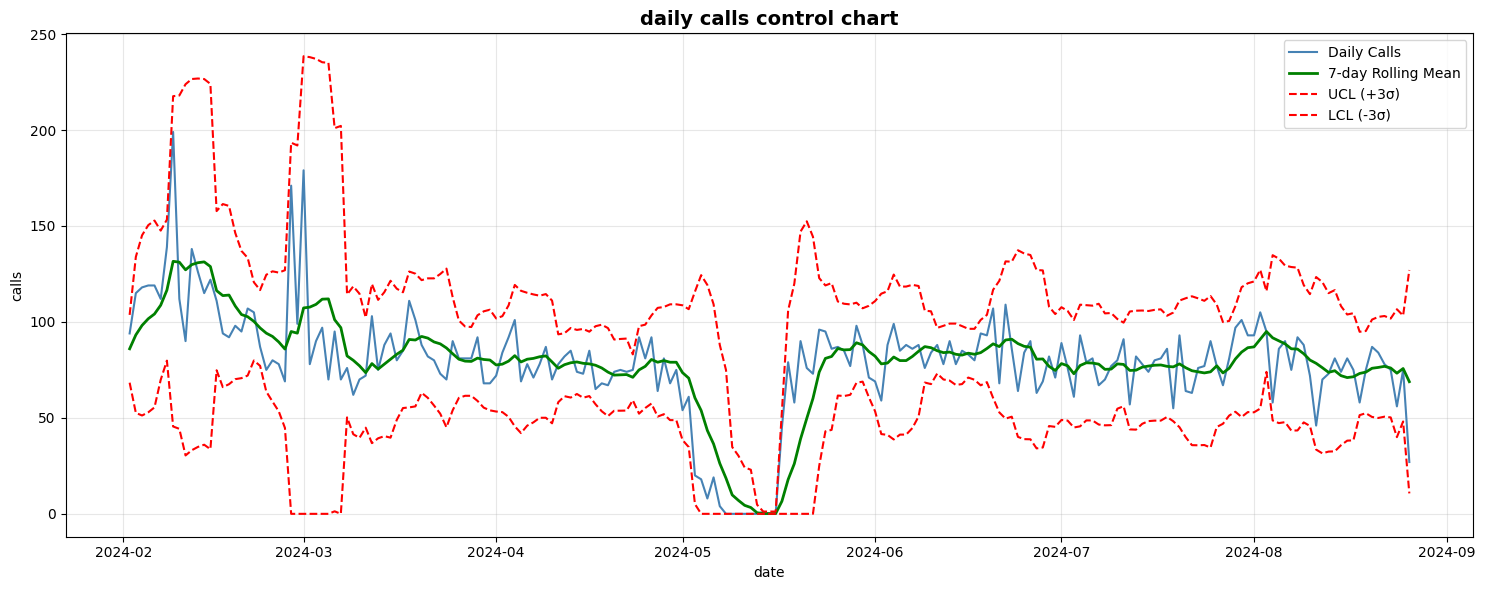

In [19]:
def prepare_daily_control_data(df, ts_col='timestamp', window=7):
    ts = pd.to_datetime(df[ts_col], errors='coerce', utc=True)
    daily = pd.Series(1, index=ts).dropna().resample('D').sum().fillna(0)

    center = daily.rolling(window=window, min_periods=3).mean()
    sigma = daily.rolling(window=window, min_periods=3).std(ddof=0)
    ucl = center + 3 * sigma
    lcl = (center - 3 * sigma).clip(lower=0)

    result = pd.DataFrame({'calls': daily, 'center': center, 'ucl': ucl, 'lcl': lcl}).dropna()
    result['is_out_of_control'] = (result['calls'] > result['ucl']) | (result['calls'] < result['lcl'])
    return result


def plot_daily_control_chart(df, ts_col='timestamp', window=7):
    ctrl = prepare_daily_control_data(df, ts_col=ts_col, window=window)

    plt.figure(figsize=(15, 6))
    plt.plot(ctrl.index, ctrl['calls'], label='Daily Calls', color='steelblue')
    plt.plot(ctrl.index, ctrl['center'], label=f'{window}-day Rolling Mean', color='green', linewidth=2)
    plt.plot(ctrl.index, ctrl['ucl'], label='UCL (+3σ)', color='red', linestyle='--')
    plt.plot(ctrl.index, ctrl['lcl'], label='LCL (-3σ)', color='red', linestyle='--')

    out_points = ctrl[ctrl['is_out_of_control']]
    if not out_points.empty:
        plt.scatter(out_points.index, out_points['calls'], color='crimson', s=40, zorder=5, label='Out-of-control')

    plt.title('daily calls control chart', fontsize=14, fontweight='bold')
    plt.xlabel('date')
    plt.ylabel('calls')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_daily_control_chart(historyCall_df_cleaned)

6. unknown data quality map

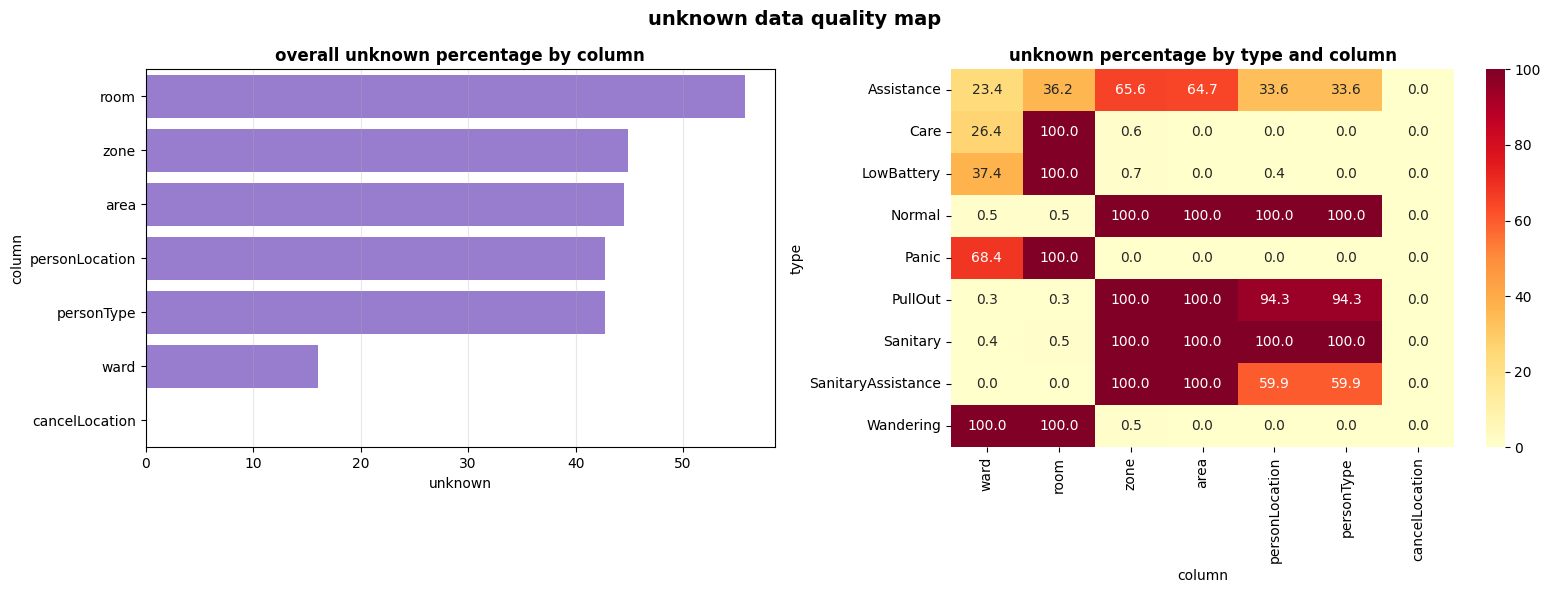

In [20]:
def compute_unknown_rate(series):
    unknown_tokens = {'unknown', 'Unknown', 'n/a', 'N/A', 'na', 'NA', '', 'None', 'none'}
    as_str = series.astype(str)
    return as_str.isin(unknown_tokens).mean() * 100


def prepare_unknown_quality_map(df, columns, type_col='type'):
    overall = {col: compute_unknown_rate(df[col]) for col in columns if col in df.columns}
    overall_df = pd.DataFrame(list(overall.items()), columns=['column', 'unknown_pct'])

    by_type_rows = []
    for t in sorted(df[type_col].dropna().unique()):
        subset = df[df[type_col] == t]
        row = {'type': t}
        for col in columns:
            if col in subset.columns:
                row[col] = compute_unknown_rate(subset[col])
        by_type_rows.append(row)

    by_type_df = pd.DataFrame(by_type_rows)
    return overall_df, by_type_df


def plot_unknown_quality_map(df):
    target_cols = ['ward', 'room', 'zone', 'area', 'personLocation', 'personType', 'cancelLocation']
    overall_df, by_type_df = prepare_unknown_quality_map(df, target_cols)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    sns.barplot(data=overall_df.sort_values('unknown_pct', ascending=False), x='unknown_pct', y='column', ax=axes[0], color='mediumpurple')
    axes[0].set_title('overall unknown percentage by column', fontweight='bold')
    axes[0].set_xlabel('unknown')
    axes[0].set_ylabel('column')
    axes[0].grid(axis='x', alpha=0.3)

    heatmap_df = by_type_df.set_index('type').fillna(0)
    sns.heatmap(heatmap_df, cmap='YlOrRd', annot=True, fmt='.1f', ax=axes[1])
    axes[1].set_title('unknown percentage by type and column', fontweight='bold')
    axes[1].set_xlabel('column')
    axes[1].set_ylabel('type')

    plt.suptitle('unknown data quality map', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_unknown_quality_map(historyCall_df_cleaned)

7. ward workload

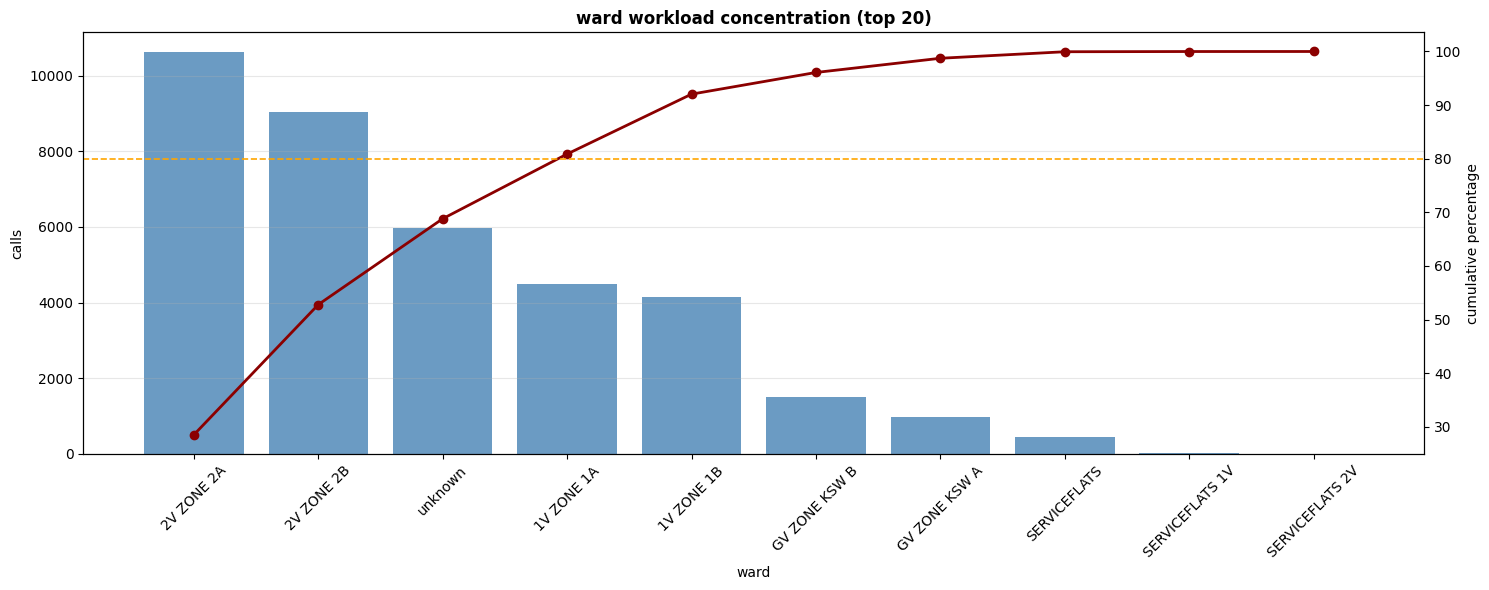

In [21]:
def prepare_ward_concentration(df, ward_col='ward'):
    ward_counts = df[ward_col].astype(str).value_counts().reset_index()
    ward_counts.columns = ['ward', 'calls']
    ward_counts['cum_pct'] = ward_counts['calls'].cumsum() / ward_counts['calls'].sum() * 100
    return ward_counts


def plot_ward_workload_concentration(df, ward_col='ward', top_n=20):
    ward_counts = prepare_ward_concentration(df, ward_col=ward_col)
    top = ward_counts.head(top_n).copy()

    fig, ax1 = plt.subplots(figsize=(15, 6))
    ax2 = ax1.twinx()

    ax1.bar(top['ward'], top['calls'], color='steelblue', alpha=0.8)
    ax2.plot(top['ward'], top['cum_pct'], color='darkred', marker='o', linewidth=2)

    ax1.set_title(f'ward workload concentration (top {top_n})', fontweight='bold')
    ax1.set_xlabel('ward')
    ax1.set_ylabel('calls')
    ax2.set_ylabel('cumulative percentage')
    ax2.axhline(80, color='orange', linestyle='--', linewidth=1.2)

    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_ward_workload_concentration(historyCall_df_cleaned)

8. response time and priority distribution

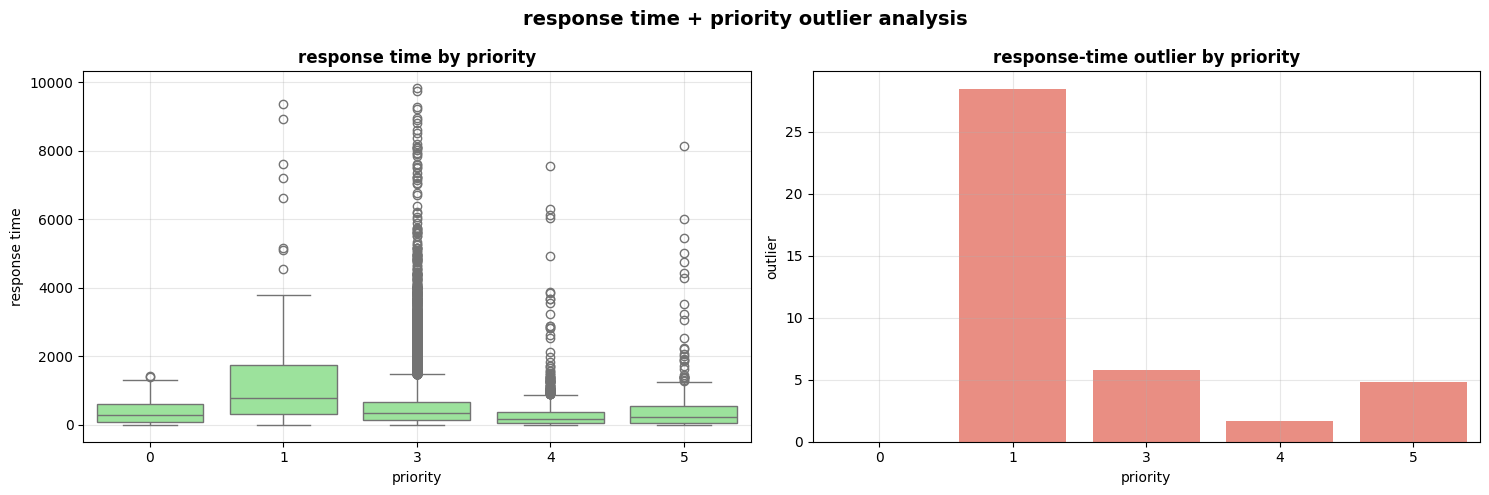

IQR: lower=-668.00, upper=1460.00


In [22]:
def prepare_response_time_seconds(df, response_col='responseTime'):
    response_raw = df[response_col].astype(str).str.extract(r'([-+]?\d*\.?\d+)')[0]
    response_numeric = pd.to_numeric(response_raw, errors='coerce')

    median_val = response_numeric.dropna().median() 
    if pd.notna(median_val) and median_val > 1e6:   # convert seconds if median suggests ticks
        response_seconds = response_numeric / 1e7
    else:
        response_seconds = response_numeric

    return response_seconds


def get_iqr_bounds(series, multiplier=1.5):
    clean = series.dropna()
    q1 = clean.quantile(0.25)
    q3 = clean.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - multiplier * iqr
    upper = q3 + multiplier * iqr
    return lower, upper


def plot_response_priority_outliers(df, priority_col='priority', response_col='responseTime'):
    tmp = df.copy()
    tmp['response_time_sec'] = prepare_response_time_seconds(tmp, response_col=response_col)

    lower, upper = get_iqr_bounds(tmp['response_time_sec'])
    tmp['is_response_outlier'] = (tmp['response_time_sec'] < lower) | (tmp['response_time_sec'] > upper)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    sns.boxplot(data=tmp, x=priority_col, y='response_time_sec', ax=axes[0], color='lightgreen')
    axes[0].set_title('response time by priority', fontweight='bold')
    axes[0].set_xlabel('priority')
    axes[0].set_ylabel('response time')
    axes[0].grid(alpha=0.3)

    outlier_summary = tmp.groupby(priority_col)['is_response_outlier'].mean().mul(100).reset_index(name='outlier_pct')
    sns.barplot(data=outlier_summary, x=priority_col, y='outlier_pct', ax=axes[1], color='salmon')
    axes[1].set_title('response-time outlier by priority', fontweight='bold')
    axes[1].set_xlabel('priority')
    axes[1].set_ylabel('outlier')
    axes[1].grid(alpha=0.3)

    plt.suptitle('response time + priority outlier analysis', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    print(f'IQR: lower={lower:.2f}, upper={upper:.2f}')

plot_response_priority_outliers(historyCall_df_cleaned)